# Example: KMT-2025-BLG-0121 — a minimum sharper than the lattice

This is one of a series of example notebooks that run lenscape's map pipeline, with its default settings, on
published planetary events. It is the fourth event of Han et al. (2026, *Four Cold Super-Jupiters Revealed by
Extended and Complex Microlensing Signals*, arXiv:2601.13450), after `example_kb200202`, `example_kb230466` and
`example_kb221551`.

**The event.** KMT-2025-BLG-0121 occurred on a bright source (*I*_base = 16.97) and peaked on HJD′ ≈ 754 (here
HJD′ = HJD − 2460000, as in the paper). After the peak the light curve has a smooth bump at HJD′ 756.2 and a sharp
caustic spike at 764.2. Han et al. report a unique solution with a resonant caustic: *s* = 1.091, *q* = 12.1 × 10⁻³,
*t*ₑ = 30.0 d, ρ = 1.13 × 10⁻³ (their Table 4).

**Why this event.** Its minimum is far sharper than the paper's lattice: half a lattice step (0.015 dex in log *s*)
costs hundreds in χ², so the 1× map ends about 150 above the best fit. The notebook starts from the stored 1× map
and zooms into the central region, log *s* −0.2 to +0.2 and log *q* −2 to −1, with three doublings (2×, 4×, 8×).

## 0. Setup

In [1]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.optimize import minimize
import lenscape
from lenscape import figures

RECOMPUTE = False              # True: compute the best fit and all maps again; False: compute only what data/ lacks
LOGFILE = os.environ.get("LENSCAPE_LOG")          # progress of long runs is also appended here if set
KEYS = ("logs", "logq", "chi2", "pars", "chi2_ref", "wall")


def log(msg):
    print(msg, flush=True)
    if LOGFILE:
        with open(LOGFILE, "a") as f:
            f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")


def run_or_load(name, compute):
    # data/kb250121_map_NAME.npz: computed (and saved) if missing or RECOMPUTE, else loaded
    path = f"data/kb250121_map_{name}.npz"
    if RECOMPUTE or not os.path.exists(path):
        log(f"computing map {name}")
        m = compute()
        np.savez_compressed(path, **{k: m[k] for k in KEYS})
        log(f"map {name}: {m['chi2'].shape}, {m['wall'] / 60:.1f} min, lowest chi2 {np.nanmin(m['chi2']):.2f}")
        return m
    return dict(np.load(path))

print("lenscape", lenscape.__version__)

lenscape 1.0


## 1. The photometry

`data/kb250121_photometry.csv` holds the data of the stored 1× map: within HJD′ 725–780 the KMTNet photometry of
Han et al. (2026) Fig. 6, read from the figure's vector graphics (their reduction, normalised error bars), and outside
that window the public KMTNet pySIS points, mapped into the same flux system. The error bars are already normalised
and five-sigma outliers removed; the flux is oriented so that brighter is up.

In [2]:
rows = np.genfromtxt("data/kb250121_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
SETS = ["KMTC19", "KMTS19", "KMTA19"]
data = lenscape.Data.from_sets({n: (rows["t"][rows["set"] == n], rows["flux"][rows["set"] == n],
                                    rows["flux_err"][rows["set"] == n]) for n in SETS})
data

Data(3175 points, t 707.88 .. 964.27, sets {'KMTC19': 1579, 'KMTS19': 850, 'KMTA19': 746})

## 2. The best fit

The best fit of these data, from the published parameters (`lenscape.fit_full`). It agrees with Table 4 of Han et
al.: *s* = 1.0912 ± 0.0026, *q* = (12.1 ± 0.74) × 10⁻³, *t*ₑ = 29.97 ± 0.54 d, ρ = (1.13 ± 0.08) × 10⁻³.

In [3]:
best = np.array([756.516537150561, -0.030768167396955655, 29.670653370468155, 0.03860251544122249,
                 -1.9036907867002437, 3.4530059822718826, -2.9724700860432565])
be = lenscape.make_backend(lenscape.config.REFINE_BACKEND)
chi2_best = lenscape.model.chi2(be, best, data)
print(f"chi2 = {chi2_best:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4] * 1e3:.2f}e-3, "
      f"tE = {best[2]:.2f} d, rho = {10 ** best[6] * 1e3:.2f}e-3")

chi2 = 3091.3 for 3175 points;  s = 1.0930, q = 12.48e-3, tE = 29.67 d, rho = 1.07e-3


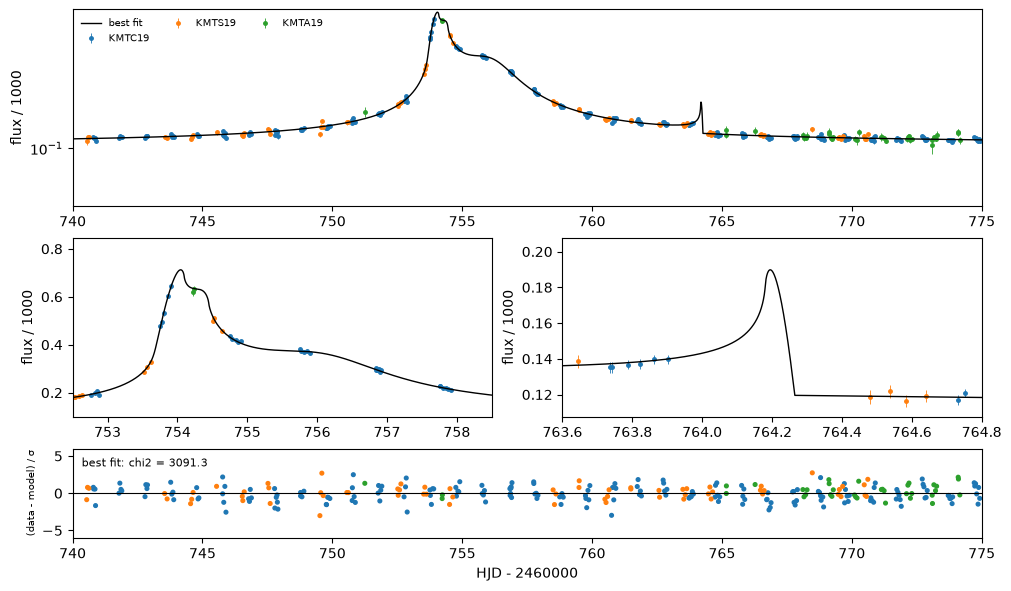

In [4]:
WINDOW, ZOOMS = (740.0, 775.0), ((752.5, 758.5), (763.6, 764.8))


def plot_flux(sols, window=WINDOW, zooms=ZOOMS, d=None):
    # data of all sets on the flux scale of the first set (aligned with the best fit), the first set's model of each
    # solution, two zooms and one panel of normalised residuals per solution (each with its own fluxes); the top
    # panel has a symmetric-log flux axis
    d = data if d is None else d
    styles = ["-", ":", "--", "-.", (0, (5, 1)), (0, (1, 3))]
    fs0, fb0 = lenscape.model.fluxes(lenscape.model.magnification(be, best, d), d)
    fig = plt.figure(figsize=(10, 4.8 + 1.0 * len(sols)), constrained_layout=True)
    gs = fig.add_gridspec(2 + len(sols), 2, height_ratios=[2.2, 2.0] + [1] * len(sols))
    top = fig.add_subplot(gs[0, :]); zax = [fig.add_subplot(gs[1, k]) for k in range(2)]
    for ax, (a, b) in zip([top] + zax, [window] + list(zooms)):
        lo, hi = [], []
        tt = np.linspace(a, b, 4000)
        for (name, p), ls in zip(sols.items(), styles):
            fs, fb = lenscape.model.fluxes(lenscape.model.magnification(be, p, d), d)
            mod = (fs[0] * be.lc(lenscape.model.clamp(p)[0], tt) + fb[0]) / 1e3
            ax.plot(tt, mod, linestyle=ls, color="k", lw=1, label=name if ax is top else None, zorder=3)
            lo.append(mod.min()); hi.append(mod.max())
        for k, name in enumerate(d.names):
            m = (d.idx == k) & (d.t > a) & (d.t < b)
            f = (d.f[m] - fb0[k]) / fs0[k] * fs0[0] + fb0[0]
            ax.errorbar(d.t[m], f / 1e3, d.e[m] * abs(fs0[0] / fs0[k]) / 1e3, fmt="o", ms=2.5, lw=0.6,
                        color=f"C{k}", label=name if ax is top else None, zorder=2)
        span = max(hi) - min(lo)
        ax.set_xlim(a, b); ax.set_ylabel("flux / 1000")
        if ax is not top:
            ax.set_ylim(min(lo) - 0.15 * span, max(hi) + 0.25 * span)
    top.set_yscale("symlog", linthresh=max(abs(fb0[0] + fs0[0]) / 1e3, 0.1))
    top.legend(fontsize=7, frameon=False, ncol=3, loc="upper left")
    for k, (name, p) in enumerate(sols.items()):
        ax = fig.add_subplot(gs[2 + k, :], sharex=top)
        r = lenscape.model.residuals(be, p, d)
        m = (d.t > window[0]) & (d.t < window[1])
        ax.scatter(d.t[m], r[m], s=7, c=[f"C{i}" for i in d.idx[m]]); ax.axhline(0, color="k", lw=0.8)
        ax.set_ylim(-6, 6); ax.set_ylabel("(data - model) / σ", fontsize=7)
        ax.text(0.01, 0.8, f"{name}: chi2 = {np.sum(r ** 2):.1f}", transform=ax.transAxes, fontsize=8)
    ax.set_xlabel(f"HJD - {2460000}")
    return fig

plot_flux({"best fit": best});

For later comparison, here is the **single-lens floor**: the χ² of the best point-lens model (with a finite source),
measured against the binary best fit. Points of a map with Δχ² near this value are no better than having no planet
or companion at all.

In [5]:
def chi2_1l1s(x):
    A = lenscape.single.lc_1l1s(x[0], x[1], abs(x[2]), 10 ** x[3], data.t, 0.0)
    fs, fb = lenscape.model.fluxes(A, data)
    return float((((data.f - fs[data.idx] * A - fb[data.idx]) / data.e) ** 2).sum())

chi2_single = min(minimize(chi2_1l1s, [best[0], u0, best[2], lr], method="Nelder-Mead",
                           options=dict(maxfev=4000, adaptive=True)).fun
                  for u0 in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3) for lr in (-3.5, -2.5, -1.5))
floor = chi2_single - chi2_best
print(f"single-lens floor: Delta chi2 = {floor:.1f}")

single-lens floor: Delta chi2 = 4023.7


## 3. The paper's map

`data/kb250121_paper_grid.csv` holds the coloured cells of Han et al.'s Fig. 2, read from the figure's vector
graphics. Their bands are Δχ² ≤ *n* × (1, 4, 9, 16) with *n* = 15, white above 240.

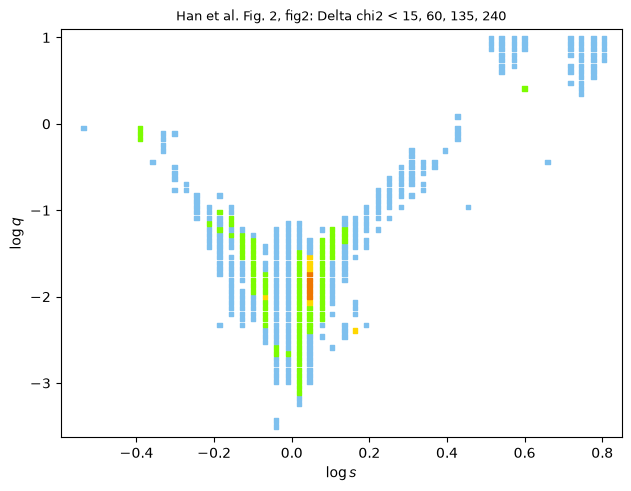

In [6]:
paper = np.genfromtxt("data/kb250121_paper_grid.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                      skip_header=2)
EDGES = np.array([15, 60, 135, 240])                         # the paper's band edges in Delta chi2
band_cmap = ListedColormap(["#ee7600", "gold", "lawngreen", "#7ec0ee"] + ["white"])        # the paper's band colours, white above the last band
PANELS = {"fig2": ((-0.5954, 0.8501), (-3.6305, 1.102))}                                 # paper panel: (log s range, log q range)
fig, axs = plt.subplots(1, len(PANELS), figsize=(6.2 * len(PANELS), 4.8), constrained_layout=True, squeeze=False)
for ax, (panel, (sr, qr)) in zip(axs[0], PANELS.items()):
    sel = paper["panel"] == panel
    ax.scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap, vmin=-0.5,
               vmax=len(EDGES) + 0.5, marker="s", s=10)
    ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
    ax.set_title(f"Han et al. Fig. 2, {panel}: Delta chi2 < " + ", ".join(f"{e:g}" for e in EDGES), fontsize=9)

## 4. Our 1× map

The 1× map on the lattice of Han et al.'s Fig. 2 plus a margin of two points (50 × 76: log *s* from −0.595 to +0.850
in steps of 0.0295, log *q* from −3.63 to +1.10 in steps of 0.0631), computed with `lenscape.lattice` and all
defaults. **It took 11.0 hours on a 6-core AMD Ryzen 5 3600 (12 threads)** and is stored in `data/`.

In [7]:
dls, dlq = 0.0295, 0.0631
logs1 = -0.5954 + dls * np.arange(50)
logq1 = -3.6305 + dlq * np.arange(76)
map1 = run_or_load("1x", lambda: lenscape.lattice(data, logs1, logq1, best=best, log=log))
OURS = [("1x", map1, "fig2")]
i, j = np.unravel_index(np.nanargmin(map1["chi2"]), map1["chi2"].shape)
print(f"{map1['chi2'].shape[0]} x {map1['chi2'].shape[1]} points, wall time {map1['wall'] / 3600:.1f} h; minimum "
      f"{map1['chi2'][i, j] - chi2_best:+.1f} against the best fit at log s = {map1['logs'][i]:.4f}, log q = {map1['logq'][j]:.3f}")

50 x 76 points, wall time 11.0 h; minimum +150.3 against the best fit at log s = 0.0536, log q = -1.611


### Our map next to the paper's

Each of our maps in the paper's bands (same band edges, no rescaling of Δχ²; the reference is the lower of our best
fit and our map minimum), next to the paper's panel of the same region:

1x: 392 coloured paper points; our band the same at 0 %, within one band at 74 %, above the last band at 99 %


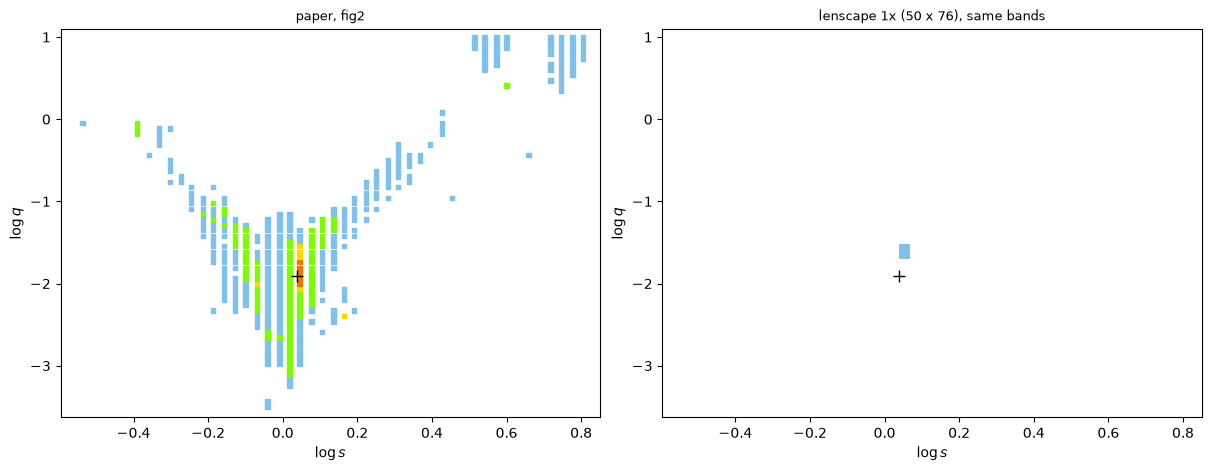

In [8]:
def lowest_ref():
    return min([chi2_best] + [float(np.nanmin(m["chi2"])) for _, m, _ in OURS])

ref = lowest_ref()
fig, axs = plt.subplots(len(OURS), 2, figsize=(12, 4.6 * len(OURS)), constrained_layout=True, squeeze=False)
for row, (name, m, panel) in enumerate(OURS):
    sr, qr = PANELS[panel]
    sel = paper["panel"] == panel
    axs[row, 0].scatter(paper["log_s"][sel], paper["log_q"][sel], c=paper["band"][sel] - 1, cmap=band_cmap,
                        vmin=-0.5, vmax=len(EDGES) + 0.5, marker="s", s=10)
    axs[row, 0].set_title(f"paper, {panel}", fontsize=9)
    band = np.searchsorted(EDGES, m["chi2"] - ref)
    axs[row, 1].pcolormesh(m["logs"], m["logq"], band.T, cmap=band_cmap, vmin=-0.5, vmax=len(EDGES) + 0.5,
                           shading="nearest")
    axs[row, 1].set_title(f"lenscape {name} ({m['chi2'].shape[0]} x {m['chi2'].shape[1]}), same bands", fontsize=9)
    for ax in axs[row]:
        ax.set_xlim(*sr); ax.set_ylim(*qr); ax.set_xlabel(r"$\log s$"); ax.set_ylabel(r"$\log q$")
        ax.plot(best[3], best[4], "k+", ms=9)

# our band at each coloured point of the paper (nearest lattice point inside our map)
for name, m, panel in OURS:
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, m["chi2"][i, j] - ref) + 1
    pb = paper["band"][sel]
    print(f"{name}: {sel.sum()} coloured paper points; our band the same at {100 * np.mean(ours == pb):.0f} %, within "
          f"one band at {100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

### Accuracy of the map values

The maps are computed with lenscape's fast grid backend (relative magnification accuracy about 3 × 10⁻³); the best
fit uses the accurate refine backend. Where many precise points sit at high magnification, the difference can reach a
few χ², which matters for band edges of 4 and 9. Here every map point is evaluated again with the refine backend at
its stored parameters (no refit: an upper bound on the accurate profile χ²), and the band comparison is repeated.
Stored in `data/`; this takes a minute or two.

In [9]:
be_exact = lenscape.make_backend(lenscape.config.REFINE_BACKEND)


def exact_chi2(name, m):
    path = f"data/kb250121_map_{name.replace(' ', '_')}_exact.npy"
    if not RECOMPUTE and os.path.exists(path):
        return np.load(path)
    ex = np.empty_like(m["chi2"])
    for i, ls in enumerate(m["logs"]):
        for j, lq in enumerate(m["logq"]):
            t0, u0, tE, al, lr = m["pars"][i, j]
            ex[i, j] = lenscape.model.chi2(be_exact, np.array([t0, u0, tE, ls, lq, al, lr]), data)
    np.save(path, ex)
    return ex


for name, m, panel in OURS:
    ex = exact_chi2(name, m)
    dd = (ex - m["chi2"])[m["chi2"] - ref < EDGES[-1]]
    print(f"{name}: accurate minus map chi2 where Delta chi2 < {EDGES[-1]:g}: median {np.median(dd):+.2f}, "
          f"5-95 % {np.percentile(dd, 5):+.2f} .. {np.percentile(dd, 95):+.2f}; accurate minimum {ex.min():.2f} "
          f"(map {np.nanmin(m['chi2']):.2f}, best fit {chi2_best:.2f})")
    rex = min(chi2_best, ex.min())
    sel = (paper["panel"] == panel) & (paper["log_s"] >= m["logs"][0]) & (paper["log_s"] <= m["logs"][-1]) \
          & (paper["log_q"] >= m["logq"][0]) & (paper["log_q"] <= m["logq"][-1])
    i = np.round((paper["log_s"][sel] - m["logs"][0]) / (m["logs"][1] - m["logs"][0])).astype(int)
    j = np.round((paper["log_q"][sel] - m["logq"][0]) / (m["logq"][1] - m["logq"][0])).astype(int)
    ours = np.searchsorted(EDGES, ex[i, j] - rex) + 1
    pb = paper["band"][sel]
    print(f"   with accurate values: band the same at {100 * np.mean(ours == pb):.0f} %, within one band at "
          f"{100 * np.mean(abs(ours - pb) <= 1):.0f} %, above the last band at {100 * np.mean(ours > len(EDGES)):.0f} %")

1x: accurate minus map chi2 where Delta chi2 < 240: median +0.29, 5-95 % +0.27 .. +0.32; accurate minimum 3241.94 (map 3241.67, best fit 3091.34)
   with accurate values: band the same at 0 %, within one band at 74 %, above the last band at 99 %


### Local minima of our map

Lattice points lower than all eight neighbours, with their Δχ² and fitted parameters, next to the published
solutions:

In [10]:
def local_minima(m, max_dchi2):
    c = m["chi2"]; out = []
    for i in range(1, c.shape[0] - 1):
        for j in range(1, c.shape[1] - 1):
            nb = c[i - 1:i + 2, j - 1:j + 2]
            if c[i, j] <= nb.min() and c[i, j] - ref < max_dchi2:
                out.append((c[i, j] - ref, m["logs"][i], m["logq"][j], m["pars"][i, j]))
    return sorted(out, key=lambda z: z[0])

for name, m, panel in OURS:
    print(f"{name}:")
    for dc, ls, lq, x in local_minima(m, EDGES[-1])[:15]:
        print(f"  Delta chi2 {dc:7.1f}  log s {ls:+.3f}  log q {lq:+.3f}  tE {abs(x[2]):6.1f} d  log rho {x[4]:+.2f}")

1x:
  Delta chi2   150.3  log s +0.054  log q -1.611  tE   24.9 d  log rho -2.73


## 5. Zoom on the central region

The box log *s* −0.2 … +0.2, log *q* −2 … −1 contains the published solution. We densify only the points of the 2×,
4× and 8× lattices inside it, each from the previous one (`lenscape.maps.densify`), so every finer map contains the
points of the coarser one.

In [11]:
def in_box(x0, step, lo, hi):
    # the points x0 + step k of a lattice axis that lie in [lo, hi]
    k = np.arange(int(np.ceil((lo - x0) / step - 1e-9)), int(np.floor((hi - x0) / step + 1e-9)) + 1)
    return x0 + step * k

BOX_S, BOX_Q = (-0.2, 0.2), (-2.0, -1.0)
zoom2 = run_or_load("zoom_2x", lambda: lenscape.maps.densify(
    [map1], data, in_box(logs1[0], dls / 2, *BOX_S), in_box(logq1[0], dlq / 2, *BOX_Q), best=best, log=log))
zoom4 = run_or_load("zoom_4x", lambda: lenscape.maps.densify(
    [zoom2], data, in_box(logs1[0], dls / 4, *BOX_S), in_box(logq1[0], dlq / 4, *BOX_Q), best=best, log=log))
zoom8 = run_or_load("zoom_8x", lambda: lenscape.maps.densify(
    [zoom4], data, in_box(logs1[0], dls / 8, *BOX_S), in_box(logq1[0], dlq / 8, *BOX_Q), best=best, log=log))
ZOOMS_K = [("1x", map1), ("zoom 2x", zoom2), ("zoom 4x", zoom4), ("zoom 8x", zoom8)]
zref = min(chi2_best, *(float(np.nanmin(m["chi2"])) for _, m in ZOOMS_K))
for name, m in ZOOMS_K:
    i, j = np.unravel_index(np.nanargmin(m["chi2"]), m["chi2"].shape)
    print(f"{name:8s}: {m['chi2'].shape[0]:3d} x {m['chi2'].shape[1]:3d} points, wall time {m['wall'] / 60:5.1f} min, "
          f"minimum {m['chi2'][i, j] - chi2_best:+8.2f} against the best fit at log s = {m['logs'][i]:.4f}, log q = {m['logq'][j]:.4f}")

computing map zoom_2x

Stage 1/3: Lattice point fits - 864 points started from the 3 nearest of 3800 known solutions

Stage 2/3: Neighbour refinement - refit points whose neighbours found a better solution
neighbour refinement: 781 points checked, 171 improved (116 by less than 1)

Stage 3/3: Recalculate outliers - deep search for points that are worse than their neighbours
recalculate outliers, pass 1: 139 outliers, 14 improved
recalculate outliers, pass 2: 41 outliers, 4 improved
recalculate outliers, pass 3: 11 outliers, 1 improved
recalculate outliers, pass 4: 4 outliers, 1 improved
recalculate outliers, pass 5: 3 outliers, 0 improved
done in 558s; lowest chi2 3091.33
map zoom_2x: (27, 32), 9.3 min, lowest chi2 3091.33
computing map zoom_4x

Stage 1/3: Lattice point fits - 3402 points started from the 3 nearest of 864 known solutions

Stage 2/3: Neighbour refinement - refit points whose neighbours found a better solution
neighbour refinement: 2101 points checked, 454 improved (424 

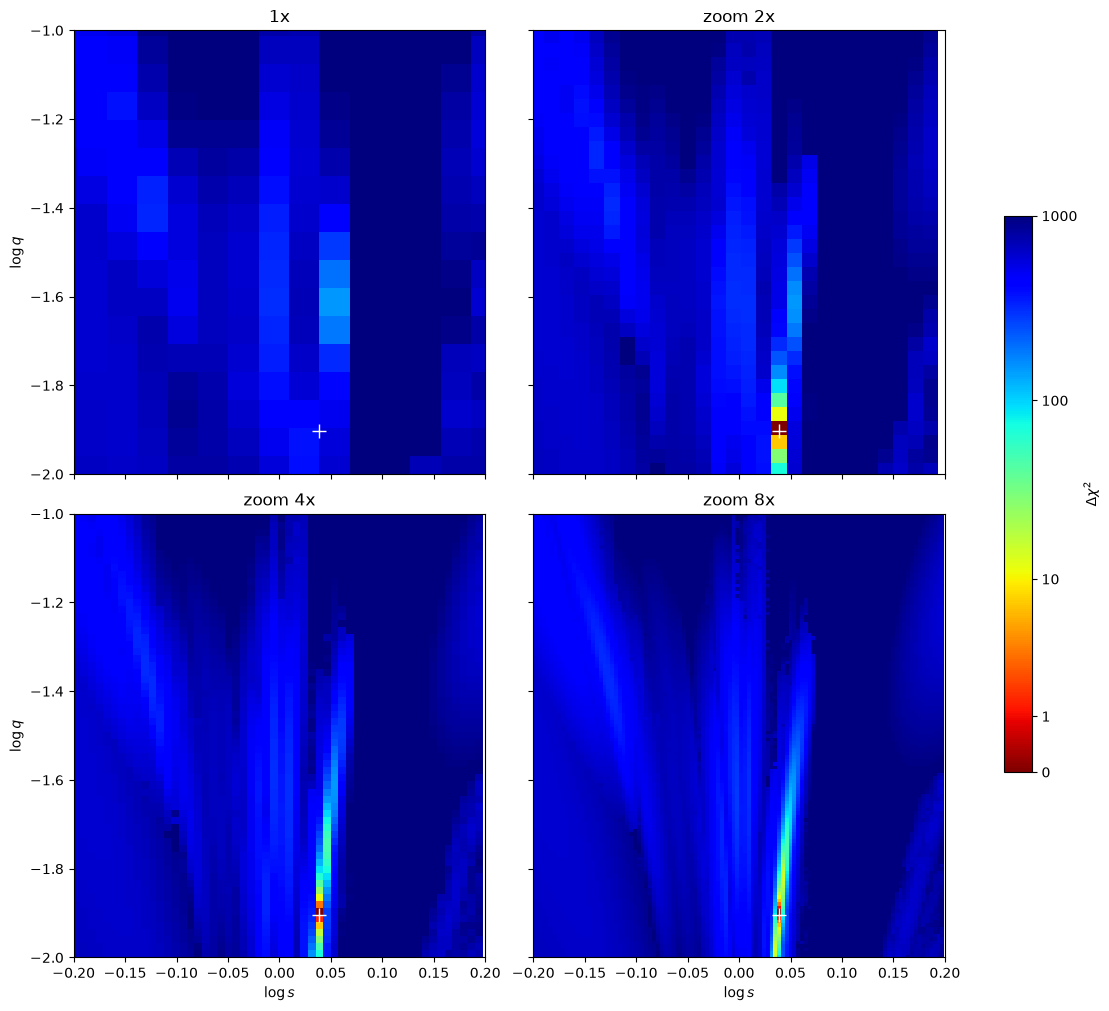

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True, sharex=True, sharey=True)
for ax, (name, m) in zip(axs.flat, ZOOMS_K):
    figures.plot_map(m, ax=ax, vmax=1000, chi2_ref=zref, colorbar=False)
    ax.plot(best[3], best[4], "w+", ms=10); ax.set_title(name)
axs[0, 0].set_xlim(*BOX_S); axs[0, 0].set_ylim(*BOX_Q)
for ax in axs[0]: ax.set_xlabel("")
for ax in axs[:, 1]: ax.set_ylabel("")
ticks = np.array([0, 1, 10, 100, 1000])
cb = fig.colorbar(axs[0, 0].images[0], ax=axs, shrink=0.6, ticks=np.log10(ticks + 1))
cb.set_ticklabels([str(t) for t in ticks]); cb.set_label(r"$\Delta\chi^2$");

Convergence at the shared points (every point of a coarser zoom is also a point of the finer one):

In [13]:
def shared(coarse, fine):
    # values of the fine map at the points of the coarse one
    i = np.round((coarse["logs"] - fine["logs"][0]) / (fine["logs"][1] - fine["logs"][0])).astype(int)
    j = np.round((coarse["logq"] - fine["logq"][0]) / (fine["logq"][1] - fine["logq"][0])).astype(int)
    return fine["chi2"][np.ix_(i, j)]

for (n1, m1), (n2, m2) in [(ZOOMS_K[1], ZOOMS_K[3]), (ZOOMS_K[2], ZOOMS_K[3])]:
    c2 = shared(m1, m2); diff = m1["chi2"] - c2
    for label, sel in [("Delta chi2 < 240", c2 - zref < 240), ("all", np.isfinite(c2))]:
        print(f"{n1} vs {n2}, {label:16s}: {sel.sum():5d} points, coarser higher by > 1 at "
              f"{100 * (diff[sel] > 1).mean():3.0f} %, by > 10 at {100 * (diff[sel] > 10).mean():3.0f} %")

zoom 2x vs zoom 8x, Delta chi2 < 240:    15 points, coarser higher by > 1 at   0 %, by > 10 at   0 %
zoom 2x vs zoom 8x, all             :   864 points, coarser higher by > 1 at  14 %, by > 10 at   4 %
zoom 4x vs zoom 8x, Delta chi2 < 240:    50 points, coarser higher by > 1 at   2 %, by > 10 at   0 %
zoom 4x vs zoom 8x, all             :  3402 points, coarser higher by > 1 at  10 %, by > 10 at   3 %


*(Comments on the zoom are written once the maps exist.)*